In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"
os.environ.setdefault("HF_HUB_CACHE", "/glazkov-dev/.cache")
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import torch
import sys, json, math, gc, copy
from pathlib import Path
from transformers import AutoTokenizer, TrainerCallback, set_seed
from peft import LoraConfig, get_peft_model, TaskType
from gptqmodel import GPTQModel
from gptqmodel.utils.backend import BACKEND
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lora_transfer_pruning").is_dir())
sys.path.insert(0, str(ROOT))
SEED = 42
set_seed(SEED)
OUTPUT_DIR = ROOT / "experiments/qlora/0_gptq_simpruning/qwen3_sp"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0), "free GiB:", torch.cuda.mem_get_info(0)[0] / 2**30)

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.

INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.

INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.          

INFO:datasets:PyTorch version 2.10.0+cu128 available.


INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.0.0+e355470
Transformers : 5.9.0
Torch        : 2.10.0+cu128
Triton       : 3.6.0

GPU: NVIDIA A100-PCIE-40GB free GiB: 38.9486083984375


In [2]:
DEVICE = "cuda:0"  # physical cuda:3 after remapping
MODEL = "Qwen/Qwen3-30B-A3B-GPTQ-Int4"

In [3]:
print(os.environ.get("HF_HUB_CACHE"))
os.environ["HF_HUB_OFFLINE"] = "1"


/glazkov-dev/.cache


## LORA CONFIG

In [4]:
FRACTION_ATTN_LAYERS = [45, 46, 47]
FRACTION_MLP_LAYERS = [45, 46, 47] 

In [5]:
config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16, 
    lora_alpha=32, 
    lora_dropout=0.0, 
    bias="none",
    target_parameters = [], #important!
    #finds nn.Parameters, but after GPTQ they are modules!
    # target_parameters=[ f"model.layers.{layer}.mlp.experts.down_proj"
    #     for layer in FRACTION_MLP_LAYERS #layers_to_transform doesnt affect on parameters
    # ], #+ ["gate_up_proj"], #"gate_up_proj"
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj", "up_proj", "down_proj", "gate_proj"],
    layers_to_transform = FRACTION_ATTN_LAYERS
)

In [6]:
print(config.target_modules)
print(config.target_parameters)

{'k_proj', 'v_proj', 'o_proj', 'up_proj', 'q_proj', 'down_proj', 'gate_proj'}
[]


## LOAD DATASET

In [7]:
from datasets import load_dataset
tokenizer = AutoTokenizer.from_pretrained(MODEL)
# Official train and validation splits; never split chunks of the same text
# between training and evaluation.
dataset = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

Using the latest cached version of the dataset since Salesforce/wikitext couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'wikitext-2-raw-v1' at /tmp/tokenicer_hf_home/datasets/Salesforce___wikitext/wikitext-2-raw-v1/0.0.0/b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Thu Nov  5 22:35:00 2026).


In [8]:
CONTEXT_LENGTH = 128
NUM_EVAL_BLOCKS = 32
EVAL_BATCH_SIZE = 1
NUM_STEPS = int(os.environ.get("QLORA_MAX_STEPS", "60"))
PRINT_EVERY = 5
EVAL_EVERY = 10
BATCH_SIZE = 1

In [9]:
from transformers import DataCollatorForLanguageModeling
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def tokenize_dataset(split):
    raw = dataset[split]
    def tokenize_function(batch):
        texts = [text for text in batch["text"] if text.strip()]
        result = tokenizer(texts, truncation=True, padding=False,
            max_length=CONTEXT_LENGTH, return_overflowing_tokens=True, stride=0)
        result.pop("overflow_to_sample_mapping", None)
        return result
    tokens = raw.map(tokenize_function, batched=True, remove_columns=raw.column_names)
    # Same rule for both splits: exclude near-empty fragments/headings.
    return tokens.filter(lambda row: len(row["input_ids"]) >= 32)

train_dataset = tokenize_dataset("train").shuffle(seed=SEED)
eval_dataset = tokenize_dataset("validation").shuffle(seed=SEED)
eval_dataset = eval_dataset.select(range(min(NUM_EVAL_BLOCKS, len(eval_dataset))))
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)
print("Train/eval samples:", len(train_dataset), len(eval_dataset))

Train/eval samples: 23094 32


In [10]:
train_dataset[1]

{'input_ids': [55166,
  320,
  330,
  358,
  8717,
  3362,
  94811,
  330,
  873,
  1154,
  714,
  806,
  4238,
  12375,
  15118,
  1200,
  88,
  1371,
  546,
  11827,
  429,
  429,
  829,
  572,
  803,
  8415,
  311,
  279,
  19373,
  84,
  3362,
  5086,
  1154,
  773,
  264,
  2664,
  829,
  1035,
  387,
  358,
  8717,
  276,
  588,
  288,
  320,
  330,
  358,
  8717,
  3362,
  569,
  12,
  31,
  1075,
  330,
  873,
  476,
  358,
  8717,
  276,
  76052,
  659,
  1260,
  50433,
  311,
  912,
  264,
  3151,
  829,
  311,
  1352,
  264,
  6169,
  9544,
  20855,
  1154,
  714,
  825,
  572,
  17221,
  304,
  220,
  16,
  23,
  17,
  24,
  553,
  79374,
  24504,
  549,
  358,
  13,
  6454,
  415,
  372,
  1154,
  892,
  572,
  2937,
  29911,
  311,
  358,
  13,
  6454,
  415,
  355,
  659,
  715],
 'attention_mask': [1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
 

## TRAINERS

In [11]:
from trl import SFTTrainer, SFTConfig
gradient_accumulation_steps = 4
learning_rate = 2e-4

class SaveHistory(TrainerCallback):
    def on_log(self, args, state, control, **kwargs):
        (OUTPUT_DIR / "history.json").write_text(json.dumps(state.log_history, indent=2))

def create_sft_trainer(model):
    args = SFTConfig(
        output_dir=str(OUTPUT_DIR), max_steps=NUM_STEPS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=gradient_accumulation_steps,
        learning_rate=learning_rate, warmup_steps=5, lr_scheduler_type="linear",
        optim="adamw_torch", max_grad_norm=1.0,
        fp16=True, bf16=False, gradient_checkpointing=False,
        logging_steps=PRINT_EVERY, logging_first_step=True,
        eval_strategy="steps", eval_steps=EVAL_EVERY,
        prediction_loss_only=True, save_strategy="no", report_to="none",
        seed=SEED, data_seed=SEED, max_length=CONTEXT_LENGTH,
        dataset_kwargs={"skip_prepare_dataset": True},
    )
    return SFTTrainer(model=model, args=args,
        train_dataset=train_dataset, eval_dataset=eval_dataset,
        processing_class=tokenizer, data_collator=data_collator,
        callbacks=[SaveHistory()])

In [12]:
# AdamW is appropriate here: only LoRA parameters are trainable.
# Trainer creates its optimizer after instrumentation, before training.

In [13]:
from unittest.mock import patch

def load_model():
    quantized_model = GPTQModel.load(MODEL, device=DEVICE,
        backend=BACKEND.GPTQ_TORCH, profile="low_memory")
    with patch("peft.utils.transformers_weight_conversion.convert_peft_config_for_transformers", return_value=None):
        peft_model = get_peft_model(quantized_model.model, copy.deepcopy(config))
    peft_model.get_base_model().config.use_cache = False
    peft_model.get_base_model().config._attn_implementation = "eager"
    return peft_model

In [14]:
# FROZE_N_LAYERS = -1 
ATTN_OUT_FRACTION = 0.3
MLP_OUT_FRACTION = 0.3
FRACTION_SEED=0

In [15]:
from transformer_lens.model_bridge.bridge import TransformerBridge
from transformer_lens.model_bridge.generalized_components.linear import LinearBridge
from lora_transfer_pruning.usecase.local_pruning import LocalPruning
from lora_transfer_pruning.core.prune_task_type import ModelPruneTask, GroupPruneTask
from lora_transfer_pruning.core.pruning_instrumentor import PruningInstrumentor

peft_model = load_model()
hf_model = peft_model.get_base_model()
peft_model.print_trainable_parameters()
expert_targets = [name for name in peft_model.base_model.targeted_module_names if ".experts." in name]
assert len(expert_targets) == len(FRACTION_MLP_LAYERS) * hf_model.config.num_experts * 3
assert all("lora_" in name for name, p in peft_model.named_parameters() if p.requires_grad)
trainable_ids = {id(p) for p in peft_model.parameters() if p.requires_grad}
bridge = TransformerBridge.boot_transformers(MODEL, hf_model=hf_model, dtype=torch.float16)
# Preserve the original PEFT trainability policy across bridge/DG setup.
for p in peft_model.parameters():
    p.requires_grad_(id(p) in trainable_ids)
trainer = create_sft_trainer(peft_model)
baseline_metrics = trainer.evaluate()
print("Before pruning:", baseline_metrics)

# TP supplies attention indices; never group.prune() packed GPTQ weights.
prune_task = ModelPruneTask({
    f"blocks.{layer}.attn.q": GroupPruneTask(None, ATTN_OUT_FRACTION)
    for layer in FRACTION_ATTN_LAYERS
}, None)
example_ids = torch.tensor(train_dataset[0]["input_ids"][:32], device=DEVICE)[None]
set_seed(FRACTION_SEED)
local_pruning = LocalPruning(bridge, example_ids)
plan = local_pruning.get_torch_pruning_groups_and_structural_setups(prune_task)
# Unknown GPTQ base operations do not stop TP propagation at Linear boundaries.
# Keep only this layer's Q/K/V output and O input adapter boundaries.
import torch_pruning as tp
from lora_transfer_pruning.adapter.torch_pruning.index_utils import IndexUtils
attention_groups = []
for layer, raw_group in zip(FRACTION_ATTN_LAYERS, plan.groups):
    attn = bridge.blocks[layer].attn
    q_idxs = list(raw_group[0].idxs)
    kv_idxs = IndexUtils.map_q_indices_to_kv(q_idxs, hf_model.config.num_attention_heads, hf_model.config.num_key_value_heads, attn._original_component.head_dim)
    targets = {}
    for name in ('q', 'k', 'v'):
        targets[getattr(attn, name)._original_component.lora_B['default']] = (True, q_idxs if name == 'q' else kv_idxs)
    targets[attn.o._original_component.lora_A['default']] = (False, q_idxs)
    group = tp.Group()
    group._DG = raw_group._DG
    found = set()
    for dep, _ in raw_group:
        if dep.target.module not in targets:
            continue
        prune_out, indices = targets[dep.target.module]
        matches = group._DG.is_out_channel_pruning_fn(dep.handler) if prune_out else group._DG.is_in_channel_pruning_fn(dep.handler)
        if matches:
            group.add_dep(dep, indices)
            found.add(dep.target.module)
    assert found == set(targets), f'Missing attention boundaries in layer {layer}'
    attention_groups.append(group)
    print(f'Layer {layer}: {len(raw_group)} raw dependencies -> {len(group)} attention boundaries')
plan.groups = attention_groups
local_pruning.prepare_model_to_transfer_pruning_from_groups(plan.groups, rescale=False)
attention_masks = {}
for group in plan.groups:
    for dep, idxs in group:
        if isinstance(dep.layer, torch.nn.Linear):
            attention_masks[str(dep.target.name) + ":" + dep.handler.__name__] = list(map(int, idxs))
print("Attention groups:", len(plan.groups))

# Unfused experts are not exposed as LinearBridge children by TL's Qwen adapter.
# Apply explicit SP masks to every expert, not only those routed in the DG trace.
# All three boundaries share the same intermediate-channel indices per expert.
expert_masks = {}
for layer in FRACTION_MLP_LAYERS:
    experts = hf_model.model.layers[layer].mlp._original_component.experts
    for expert_idx, expert in enumerate(experts):
        width = expert.up_proj.out_features
        idxs = torch.randperm(width, device=DEVICE)[:int(width * MLP_OUT_FRACTION)].sort().values
        expert_masks[f"{layer}.{expert_idx}"] = idxs.cpu().tolist()
        for projection in ("gate_proj", "up_proj", "down_proj"):
            component = LinearBridge(name=projection)
            component.set_original_component(getattr(expert, projection))
            setattr(expert, projection, component)
            PruningInstrumentor.prepare_linear_for_pruning(
                component, idxs if projection == "down_proj" else None,
                None if projection == "down_proj" else idxs, rescale=False)
del plan, local_pruning, group, dep, example_ids, raw_group, attention_groups
unexpected_trainable = [name for name, p in peft_model.named_parameters() if p.requires_grad and id(p) not in trainable_ids]
print('Non-adapter parameters enabled during setup:', unexpected_trainable[:10], 'total:', len(unexpected_trainable))
for p in peft_model.parameters():
    p.requires_grad_(id(p) in trainable_ids)
assert {id(p) for p in peft_model.parameters() if p.requires_grad} == trainable_ids
gc.collect()
torch.cuda.empty_cache()
assert all("lora_" in name for name, p in peft_model.named_parameters() if p.requires_grad)
(OUTPUT_DIR / "pruning_masks.json").write_text(json.dumps({"attention": attention_masks, "experts": expert_masks}))
pruned_metrics = trainer.evaluate()
print("After pruning, before training:", pruned_metrics)

from_quantized: adapter: None


INFO  Patched transformers.models.qwen3_moe.modeling_qwen3_moe.Qwen3MoeSparseMoeBlock -> defuser.modeling.unfused_moe.qwen3_moe.LinearQwen3MoeSparseMoeBlock

INFO  Loader: Auto dtype (native float16): `torch.float16`                     

INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: model_name_or_path.

INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: model_file_base_name.

INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_1og4y5al`

... (19 outputs left out)

/glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch_pruning/dependency/graph.py:390: UserWarning: Unwrapped parameters detected: ['model.layers.3._original_component.self_attn._original_component.q_norm._original_component.weight', 'model.layers.5._original_component.post_attention_layernorm._original_component.weight', 'model.layers.6._original_component.input_layernorm._original_component.weight', 'model.layers.13._original_component.self_attn._original_component.k_norm._original_component.weight', 'model.layers.15._original_component.self_attn._original_component.k_norm._original_component.weight', 'model.layers.30._original_component.self_attn._original_component.q_norm._original_component.weight', 'model.layers.41._original_component.post_attention_layernorm._original_component.weight', 'model.layers.44._original_component.post_attention_layernorm._original_component.weight', 'model.layers.10._original_component.self_attn._original_component.k_norm._origina

Layer 45: 6448 raw dependencies -> 4 attention boundaries
Layer 46: 6448 raw dependencies -> 4 attention boundaries
Layer 47: 6448 raw dependencies -> 4 attention boundaries
Attention groups: 3


Non-adapter parameters enabled during setup: [] total: 0


{'eval_loss': '3.116', 'eval_model_preparation_time': '0.8301', 'eval_runtime': '97.28', 'eval_samples_per_second': '0.329', 'eval_steps_per_second': '0.329', 'eval_entropy': '2.062', 'eval_num_tokens': '0', 'eval_mean_token_accuracy': '0.4406', 'epoch': 0}
After pruning, before training: {'eval_loss': 3.1160407066345215, 'eval_model_preparation_time': 0.8301, 'eval_runtime': 97.2772, 'eval_samples_per_second': 0.329, 'eval_steps_per_second': 0.329}


In [16]:
train_result = trainer.train()
# Reuse evaluation at the last optimizer step; avoid evaluating it twice.
final_metrics = next((row for row in reversed(trainer.state.log_history) if row.get("step") == trainer.state.global_step and "eval_loss" in row), None)
if final_metrics is None:
    final_metrics = trainer.evaluate()
out_history = [{**pruned_metrics, "step": 0, "epoch": 0.0}] + trainer.state.log_history
(OUTPUT_DIR / "history.json").write_text(json.dumps(out_history, indent=2))
summary = dict(model=MODEL, physical_gpu=3, seed=SEED, pruning_seed=FRACTION_SEED,
    attn_layers=FRACTION_ATTN_LAYERS, mlp_layers=FRACTION_MLP_LAYERS,
    attn_ratio=ATTN_OUT_FRACTION, mlp_ratio=MLP_OUT_FRACTION,
    steps=trainer.state.global_step, learning_rate=learning_rate,
    context_length=CONTEXT_LENGTH, effective_batch_size=BATCH_SIZE * gradient_accumulation_steps,
    baseline=baseline_metrics, pruned=pruned_metrics, trained=final_metrics)
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
for label, metrics in [("Original + zero-init LoRA", baseline_metrics), ("SP before training", pruned_metrics), ("SP after training", final_metrics)]:
    print(f"{label}: loss={metrics['eval_loss']:.5f}, perplexity={math.exp(metrics['eval_loss']):.3f}")
assert math.isfinite(final_metrics["eval_loss"])
print("Peak allocated GiB:", torch.cuda.max_memory_allocated() / 2**30)

{'loss': '2.656', 'grad_norm': '0.5716', 'learning_rate': '0', 'entropy': '2.031', 'num_tokens': '356', 'mean_token_accuracy': '0.4791', 'epoch': '0.0001732'}


{'loss': '2.824', 'grad_norm': '0.5876', 'learning_rate': '0.00016', 'entropy': '1.904', 'num_tokens': '2073', 'mean_token_accuracy': '0.4629', 'epoch': '0.000866'}


{'loss': '3.215', 'grad_norm': '0.6476', 'learning_rate': '0.0001855', 'entropy': '2.143', 'num_tokens': '4242', 'mean_token_accuracy': '0.4217', 'epoch': '0.001732'}


{'eval_loss': '2.99', 'eval_model_preparation_time': '0.8301', 'eval_runtime': '98.24', 'eval_samples_per_second': '0.326', 'eval_steps_per_second': '0.326', 'eval_entropy': '2.377', 'eval_num_tokens': '4242', 'eval_mean_token_accuracy': '0.4487', 'epoch': '0.001732'}


{'loss': '2.724', 'grad_norm': '0.7412', 'learning_rate': '0.0001673', 'entropy': '2.182', 'num_tokens': '6482', 'mean_token_accuracy': '0.4659', 'epoch': '0.002598'}


{'loss': '2.803', 'grad_norm': '0.6678', 'learning_rate': '0.0001491', 'entropy': '2.691', 'num_tokens': '8499', 'mean_token_accuracy': '0.4596', 'epoch': '0.003464'}


... (9 outputs left out)

{'eval_loss': '2.789', 'eval_model_preparation_time': '0.8301', 'eval_runtime': '94.62', 'eval_samples_per_second': '0.338', 'eval_steps_per_second': '0.338', 'eval_entropy': '2.999', 'eval_num_tokens': '2.09e+04', 'eval_mean_token_accuracy': '0.4583', 'epoch': '0.00866'}


{'loss': '2.602', 'grad_norm': '0.6991', 'learning_rate': '2.182e-05', 'entropy': '2.807', 'num_tokens': '2.276e+04', 'mean_token_accuracy': '0.4764', 'epoch': '0.009526'}


{'loss': '2.621', 'grad_norm': '0.732', 'learning_rate': '3.636e-06', 'entropy': '2.908', 'num_tokens': '2.461e+04', 'mean_token_accuracy': '0.4787', 'epoch': '0.01039'}


{'eval_loss': '2.783', 'eval_model_preparation_time': '0.8301', 'eval_runtime': '95.32', 'eval_samples_per_second': '0.336', 'eval_steps_per_second': '0.336', 'eval_entropy': '2.972', 'eval_num_tokens': '2.461e+04', 'eval_mean_token_accuracy': '0.4606', 'epoch': '0.01039'}
{'train_runtime': '1509', 'train_samples_per_second': '0.159', 'train_steps_per_second': '0.04', 'train_loss': '2.748', 'epoch': '0.01039'}
Original + zero-init LoRA: loss=3.02716, perplexity=20.639
SP before training: loss=3.11604, perplexity=22.557
SP after training: loss=2.78325, perplexity=16.171
Peak allocated GiB: 19.266567707061768


In [17]:
def plot_training_history(history, *, title="Training dynamics"):
    """Plot interleaved Trainer train/eval logs in one figure."""
    import math
    import numbers
    import matplotlib.pyplot as plt

    if not history:
        raise ValueError("history is empty")

    aliases = {"gradient_norm": "grad_norm"}
    excluded = {
        "step", "epoch", "train_loss", "train_runtime",
        "train_samples_per_second", "train_steps_per_second",
        "eval_runtime", "eval_samples_per_second",
        "eval_steps_per_second", "eval_model_preparation_time", "total_flos",
    }

    series = {}
    for row in history:
        if not isinstance(row.get("step"), numbers.Number):
            continue
        step = row["step"]
        for raw_key, value in row.items():
            if raw_key in excluded or not isinstance(value, numbers.Number):
                continue
            split = "eval" if raw_key.startswith("eval_") else "train"
            metric = raw_key.removeprefix("eval_")
            metric = aliases.get(metric, metric)
            series.setdefault(metric, {}).setdefault(split, []).append(
                (step, float(value))
            )

    # Trainer normally logs loss but not perplexity. Derive it separately
    # for train and eval, so exp(mean loss) is shown at the same steps.
    if "loss" in series and "perplexity" not in series:
        series["perplexity"] = {
            split: [
                (step, math.exp(value) if value < 80 else math.inf)
                for step, value in points
            ]
            for split, points in series["loss"].items()
        }

    preferred_order = [
        "loss", "perplexity", "grad_norm", "learning_rate",
        "mean_token_accuracy", "entropy", "num_tokens",
    ]
    metric_names = [name for name in preferred_order if name in series]
    metric_names += [name for name in series if name not in metric_names]
    if not metric_names:
        raise ValueError("history contains no step-wise numeric metrics")

    labels = {
        "loss": "Loss",
        "perplexity": "Perplexity",
        "grad_norm": "Gradient norm",
        "learning_rate": "Learning rate",
        "mean_token_accuracy": "Mean token accuracy",
        "entropy": "Entropy",
        "num_tokens": "Processed tokens",
    }
    ncols = min(2, len(metric_names))
    nrows = math.ceil(len(metric_names) / ncols)
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(7 * ncols, 4 * nrows),
        squeeze=False,
        sharex=True,
    )
    flat_axes = list(axes.flat)

    styles = {
        "train": dict(marker="o", linewidth=1.8, alpha=0.8),
        "eval": dict(marker="s", linewidth=2.4, linestyle="--"),
    }
    for ax, metric_name in zip(flat_axes, metric_names):
        label = labels.get(
            metric_name,
            metric_name.replace("_", " ").title(),
        )
        for split in ("train", "eval"):
            points = series[metric_name].get(split, [])
            if not points:
                continue
            steps, values = zip(*points)
            ax.plot(
                steps,
                values,
                label=split.capitalize(),
                **styles[split],
            )

        ax.set(
            title=label,
            xlabel="Optimizer step",
            ylabel=label,
        )
        ax.grid(True, alpha=0.3)
        ax.legend()

        if metric_name == "learning_rate":
            ax.ticklabel_format(
                axis="y",
                style="sci",
                scilimits=(0, 0),
            )

    for ax in flat_axes[len(metric_names):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    return fig, axes

INFO:matplotlib.font_manager:generated new fontManager


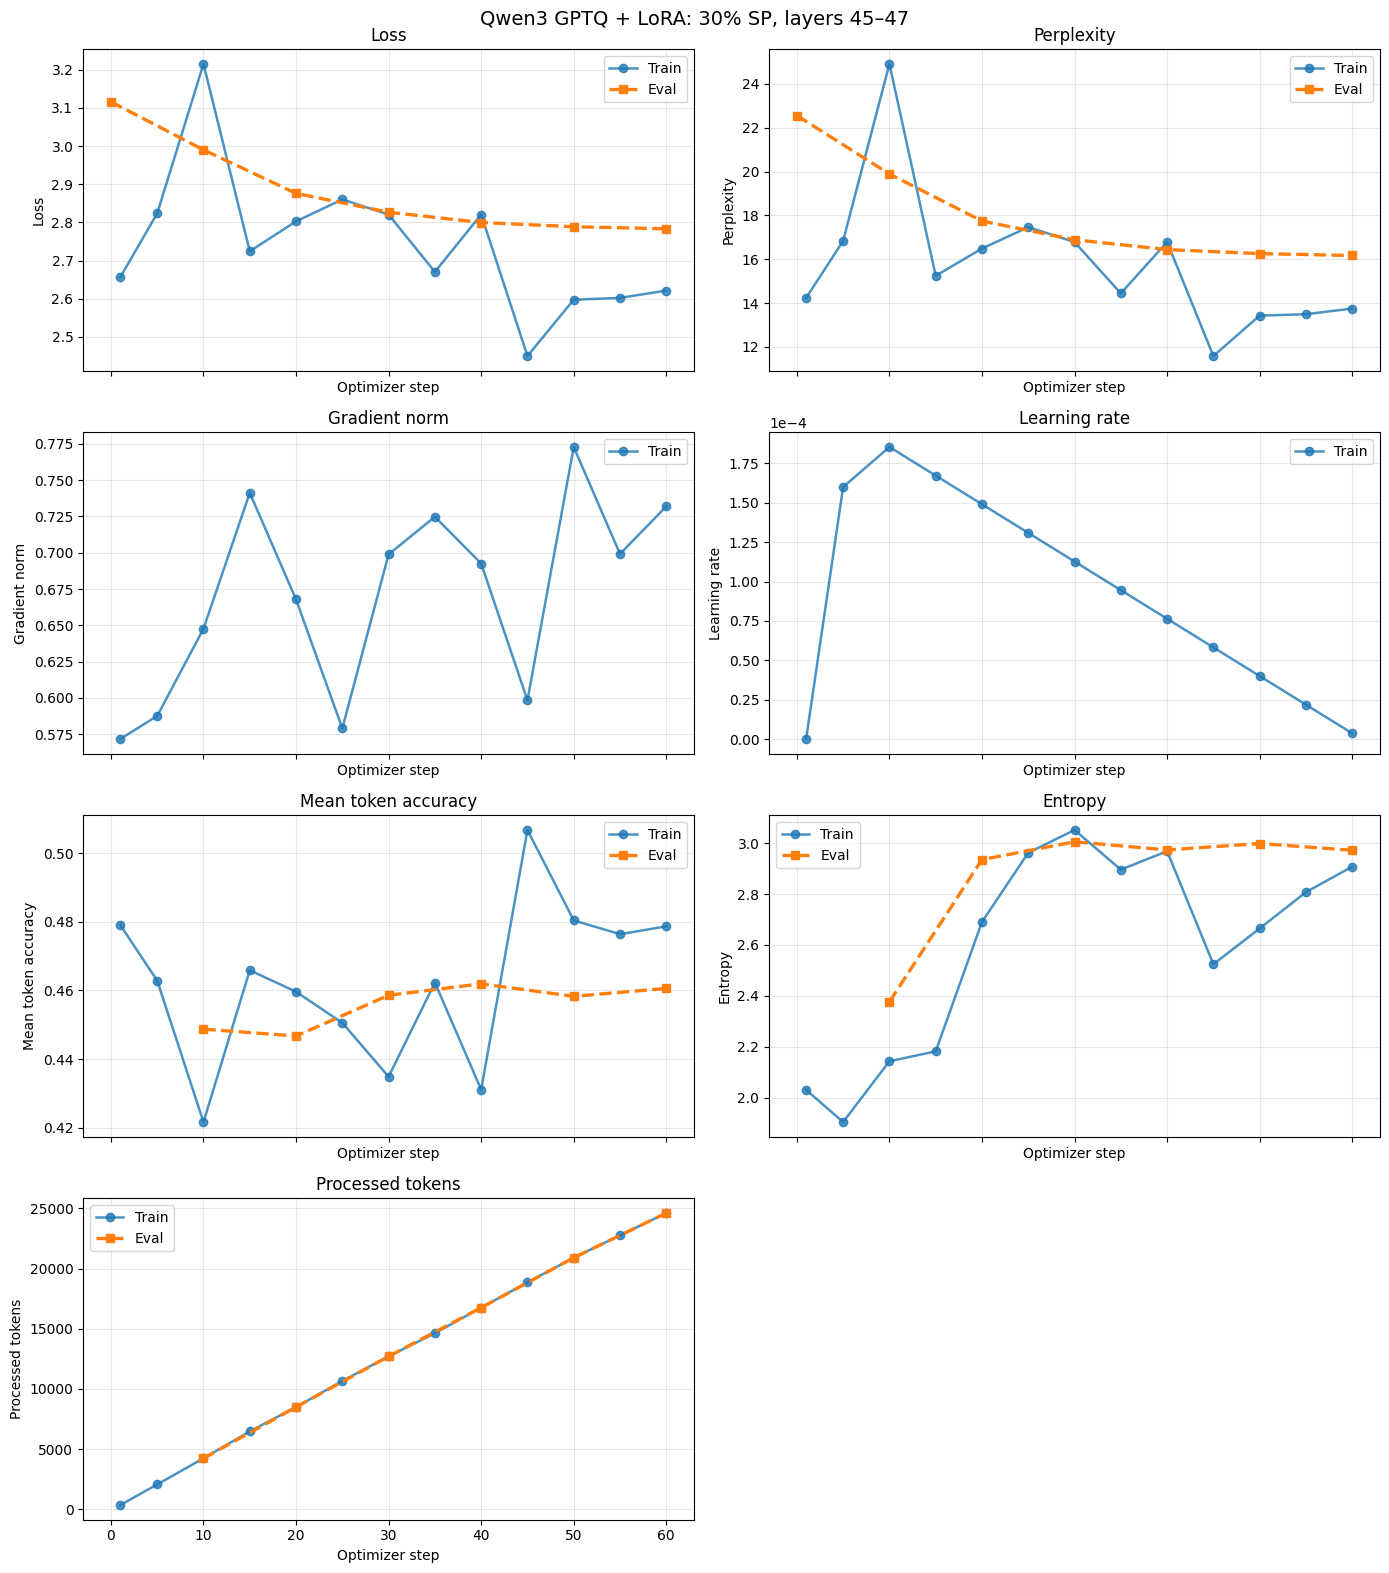

In [18]:
fig, axes = plot_training_history(out_history, title="Qwen3 GPTQ + LoRA: 30% SP, layers 45–47")
fig.savefig(OUTPUT_DIR / "training_history.png", dpi=150, bbox_inches="tight")
import matplotlib.pyplot as plt
plt.show()

## Interpretation
Raw train logs and a fixed held-out validation subset are plotted without smoothing.
Validation before pruning, after pruning, and after training is reported separately.
Only adapters train; GPTQ weights are never structurally sliced. Attention SP uses
TP groups; MoE SP uses explicit per-expert intermediate masks, including unrouted experts.
This experiment demonstrates training behavior, not equivalence to structural GPTQ pruning.
No checkpoints are saved. Metrics and masks are saved under `0_gptq_simpruning/qwen3_sp`.